# 04 — Final Evaluation: Next-Day Air Quality (Delhi)

This notebook evaluates the saved Phase C regression predictions and independently reruns the three classification models on the same chronological test period. It writes final metric tables and figures under `results/`.

**Evaluation period:** target dates 2020-01-01 through 2020-07-01. The source dataset ends on 2020-07-01, so the target date is formed as source date + 1 day and the test mask is capped at 2020-07-01. No random shuffle is used.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
RESULTS = ROOT / 'results '
PHASE_C = RESULTS / 'phase-c'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
raw_path = ROOT / 'DATA[' / 'RAW[' / 'city_day.csv'
features_path = PHASE_C / 'delhi_regression_features.csv'
reg_predictions_path = PHASE_C / 'regression_predictions.csv'
for p in [raw_path, features_path, reg_predictions_path]:
    if not p.exists(): raise FileNotFoundError(p)
features_df = pd.read_csv(features_path, parse_dates=['Date']).sort_values('Date')
reg_pred = pd.read_csv(reg_predictions_path, parse_dates=['Date']).sort_values('Date')
print('Regression features:', features_df.shape)
print('Regression predictions:', reg_pred.shape, reg_pred.Date.min().date(), 'to', reg_pred.Date.max().date())

raw = pd.read_csv(raw_path, parse_dates=['Date'])


Regression features: (2006, 15)
Regression predictions: (182, 6) 2020-01-01 to 2020-06-30


## 1. Regression metrics and persistence comparison

The persistence forecast is `tomorrow PM2.5 = today's PM2.5`. All regression models and the baseline must be scored on the exact same saved target dates. Lower MAE/RMSE is better; higher R² is better.

In [2]:
name_map={'Linear_Regression':'Linear Regression','Ridge_Regression':'Ridge','Lasso_Regression':'Lasso'}
reg_rows=[]
y=reg_pred['Actual_PM2.5']
for col in ['Persistence','Linear_Regression','Ridge_Regression','Lasso_Regression']:
    pred=reg_pred[col]
    reg_rows.append({'task':'regression','model':name_map.get(col,col),'test_rows':len(y),'MAE':mean_absolute_error(y,pred),'RMSE':np.sqrt(mean_squared_error(y,pred)),'R2':r2_score(y,pred)})
reg_metrics=pd.DataFrame(reg_rows).sort_values('RMSE').reset_index(drop=True)
base=reg_metrics.loc[reg_metrics.model.eq('Persistence')].iloc[0]
reg_metrics['MAE_improvement_vs_persistence_pct']=100*(base.MAE-reg_metrics.MAE)/base.MAE
reg_metrics['RMSE_improvement_vs_persistence_pct']=100*(base.RMSE-reg_metrics.RMSE)/base.RMSE
reg_metrics.to_csv(RESULTS/'regression_metrics_final.csv',index=False)
reg_metrics.round(4)


,task,model,test_rows,MAE,RMSE,R2,MAE_improvement_vs_persistence_pct,RMSE_improvement_vs_persistence_pct
0,regression,Ridge,182,18.1286,24.9989,0.7646,5.3740,10.7260
1,regression,Linear Regression,182,18.1266,24.9995,0.7646,5.3847,10.7239
2,regression,Lasso,182,18.1339,25.0001,0.7645,5.3462,10.7218
3,regression,Persistence,182,19.1582,28.0025,0.7046,0.0000,0.0000


In [3]:
# Verify persistence against the feature table used to create these saved predictions.
# Here Date is the feature-day t; Actual_PM2.5 is PM2.5 at t+1, and Persistence is PM2.5 at t.
lookup=features_df.set_index('Date')['PM2.5_current']
expected=reg_pred['Date'].map(lookup)
mask=expected.notna()
assert np.allclose(reg_pred.loc[mask,'Persistence'],expected[mask])
print(f'Verified persistence alignment on {mask.sum()} saved test rows.')


Verified persistence alignment on 182 saved test rows.


## 2. Predicted versus actual PM2.5 and error analysis

The next plots show how the best model by RMSE compares with actual observations. The largest absolute-error dates are listed to make model failure visible rather than hiding it behind one average score.

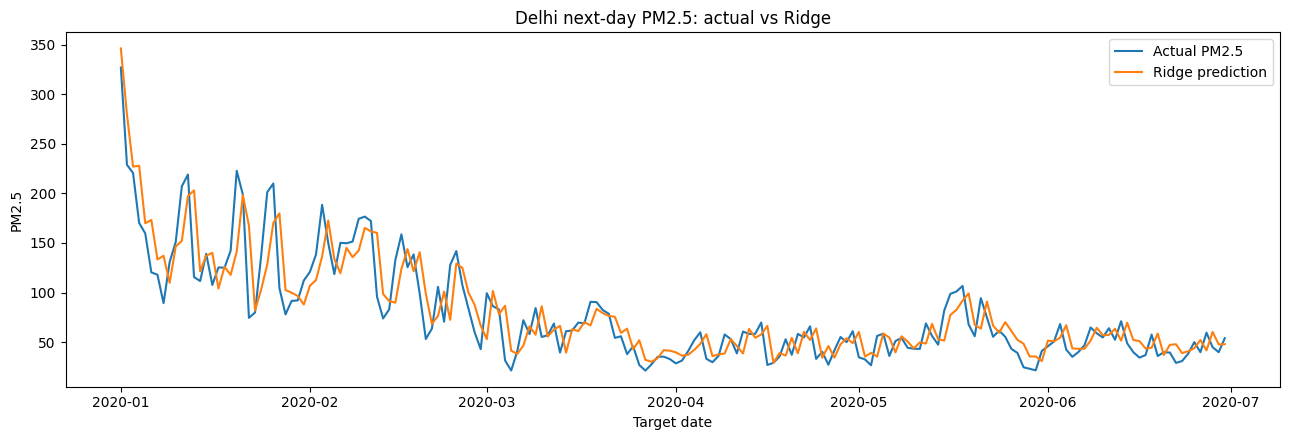

,Date,Actual_PM2.5,Ridge_Regression,absolute_error
21,2020-01-22,74.45,167.468253,93.018253
12,2020-01-13,115.62,203.069228,87.449228
19,2020-01-20,222.81,141.405591,81.404409
26,2020-01-27,104.45,179.867801,75.417801
24,2020-01-25,201.20,128.231894,72.968106
42,2020-02-12,95.72,160.168333,64.448333
3,2020-01-04,170.21,227.889531,57.679531
54,2020-02-24,127.75,72.457522,55.292478
63,2020-03-04,31.43,86.702842,55.272842
10,2020-01-11,207.23,152.137817,55.092183


In [4]:
best=reg_metrics.iloc[0]['model']
col={'Linear Regression':'Linear_Regression','Ridge':'Ridge_Regression','Lasso':'Lasso_Regression','Persistence':'Persistence'}[best]
fig,ax=plt.subplots(figsize=(13,4.5)); ax.plot(reg_pred.Date,reg_pred['Actual_PM2.5'],label='Actual PM2.5'); ax.plot(reg_pred.Date,reg_pred[col],label=f'{best} prediction'); ax.set(title=f'Delhi next-day PM2.5: actual vs {best}',xlabel='Target date',ylabel='PM2.5'); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES/'final_regression_actual_vs_predicted.png',dpi=160); plt.show()
err=reg_pred[['Date','Actual_PM2.5',col]].copy(); err['absolute_error']=(err['Actual_PM2.5']-err[col]).abs(); err.sort_values('absolute_error',ascending=False).head(15).to_csv(RESULTS/'largest_regression_errors.csv',index=False); err.sort_values('absolute_error',ascending=False).head(10)


## 3. Classification evaluation

Target: next-day `AQI_Bucket`. We preserve the chronological split and use class weights to address imbalance; the test data is not oversampled. Accuracy is reported but is not the main selection metric because a model can perform well on common buckets and poorly on rare buckets. Macro-F1 weights each class equally.

In [5]:
# Build leakage-safe classification features directly from Delhi daily data.
pollutants=['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene']
df=raw.loc[raw.City.eq('Delhi')].copy().sort_values('Date').drop_duplicates('Date').set_index('Date')
df=df.reindex(pd.date_range(df.index.min(),df.index.max(),freq='D')); df.index.name='Date'
feat=pd.DataFrame(index=df.index)
for c in pollutants:
    if c in df:
        for lag in [1,2,3,7]: feat[f'{c}_lag{lag}']=df[c].shift(lag)
for w in [3,7]:
    feat[f'PM2.5_roll{w}_mean']=df['PM2.5'].shift(1).rolling(w,min_periods=1).mean()
    feat[f'PM2.5_roll{w}_std']=df['PM2.5'].shift(1).rolling(w,min_periods=2).std()
feat['month']=feat.index.month; feat['day_of_week']=feat.index.dayofweek
doy=feat.index.dayofyear; feat['doy_sin']=np.sin(2*np.pi*doy/365.25); feat['doy_cos']=np.cos(2*np.pi*doy/365.25)
feat['AQI_Bucket_tomorrow']=df['AQI_Bucket'].shift(-1)
feat['target_date']=feat.index+pd.Timedelta(days=1)
train=(feat.target_date<pd.Timestamp('2020-01-01')) & feat.AQI_Bucket_tomorrow.notna()
test=(feat.target_date>=pd.Timestamp('2020-01-01')) & (feat.target_date<=pd.Timestamp('2020-07-01')) & feat.AQI_Bucket_tomorrow.notna()
Xcols=[c for c in feat.columns if c not in ['AQI_Bucket_tomorrow','target_date']]
X_train,X_test=feat.loc[train,Xcols],feat.loc[test,Xcols]; y_train=feat.loc[train,'AQI_Bucket_tomorrow'].astype(str); y_test=feat.loc[test,'AQI_Bucket_tomorrow'].astype(str)
print('Classification train/test:',len(y_train),len(y_test)); print(y_test.value_counts())


Classification train/test: 1815 183
AQI_Bucket_tomorrow
Moderate        98
Poor            35
Satisfactory    25
Very Poor       22
Severe           3
Name: count, dtype: int64


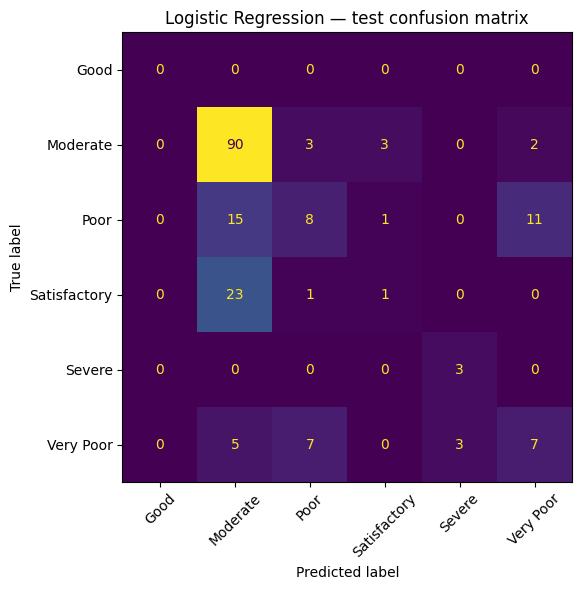

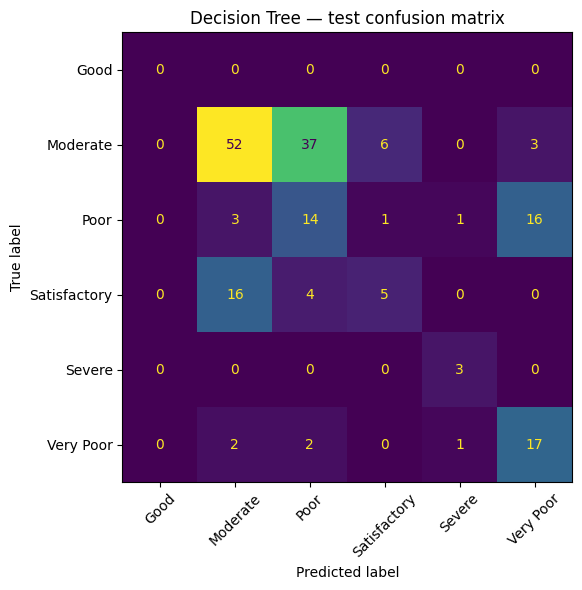

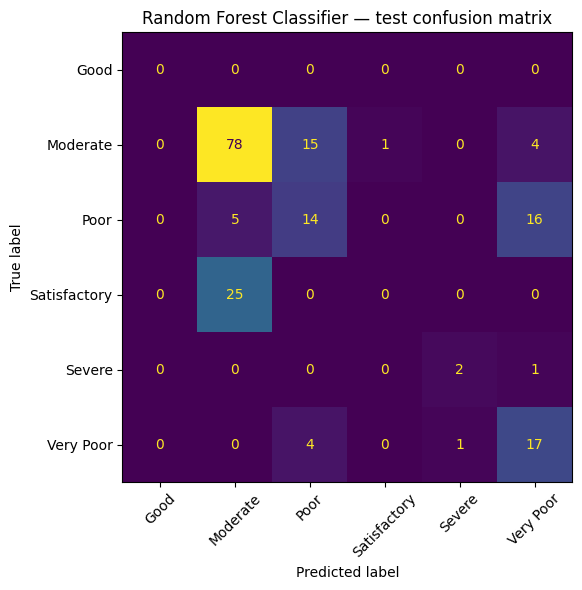

,task,model,test_rows,accuracy,macro_F1,macro_OvR_AUC_available_classes,AUC_classes_evaluated
1,classification,Decision Tree,183,0.4973,0.4198,0.7827,5
2,classification,Random Forest Classifier,183,0.6066,0.4004,0.8411,5
0,classification,Logistic Regression,183,0.5956,0.3570,0.7930,5


In [6]:
classifiers={
'Logistic Regression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=3000,class_weight='balanced',random_state=42))]),
'Decision Tree':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',DecisionTreeClassifier(max_depth=8,min_samples_leaf=5,class_weight='balanced',random_state=42))]),
'Random Forest Classifier':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=200,min_samples_leaf=3,class_weight='balanced_subsample',random_state=42,n_jobs=-1))])}
labels=sorted(set(y_train)|set(y_test)); cls_rows=[]; fitted={}
for name,clf in classifiers.items():
    clf.fit(X_train,y_train); fitted[name]=clf; pred=clf.predict(X_test)
    report=classification_report(y_test,pred,labels=labels,zero_division=0,output_dict=True); pd.DataFrame(report).T.to_csv(RESULTS/f'{name.lower().replace(" ","_")}_per_class_final.csv')
    cm=confusion_matrix(y_test,pred,labels=labels); fig,ax=plt.subplots(figsize=(7,6)); ConfusionMatrixDisplay(cm,display_labels=labels).plot(ax=ax,xticks_rotation=45,colorbar=False); ax.set_title(f'{name} — test confusion matrix'); fig.tight_layout(); fig.savefig(FIGURES/f'{name.lower().replace(" ","_")}_confusion_final.png',dpi=160); plt.show()
    probs=clf.predict_proba(X_test); aucs=[]
    for j,label in enumerate(clf.classes_):
        binary=(y_test.to_numpy()==label).astype(int)
        if len(np.unique(binary))==2: aucs.append(roc_auc_score(binary,probs[:,j]))
    cls_rows.append({'task':'classification','model':name,'test_rows':len(y_test),'accuracy':accuracy_score(y_test,pred),'macro_F1':f1_score(y_test,pred,labels=labels,average='macro',zero_division=0),'macro_OvR_AUC_available_classes':np.mean(aucs),'AUC_classes_evaluated':len(aucs)})
cls_metrics=pd.DataFrame(cls_rows).sort_values('macro_F1',ascending=False); cls_metrics.to_csv(RESULTS/'classification_metrics_final.csv',index=False); cls_metrics.round(4)


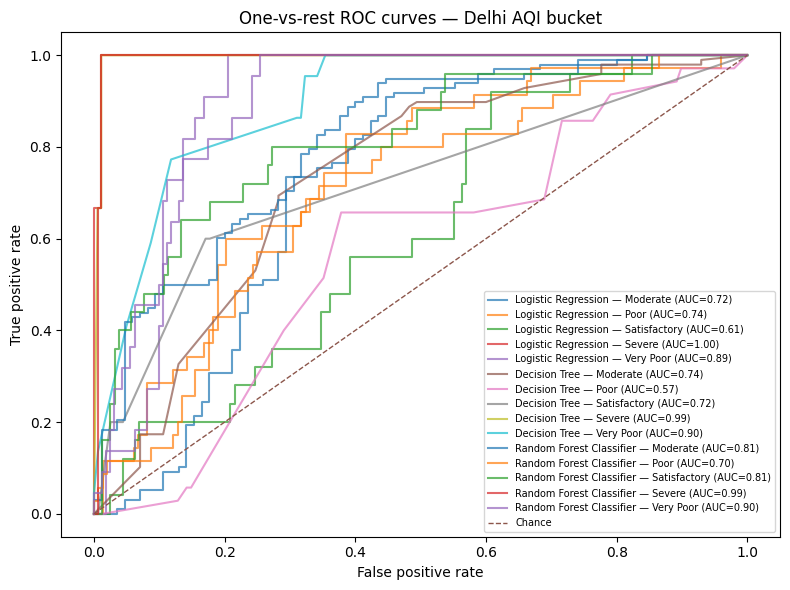

In [7]:
fig,ax=plt.subplots(figsize=(8,6))
for name,clf in fitted.items():
    probs=clf.predict_proba(X_test)
    for j,label in enumerate(clf.classes_):
        binary=(y_test.to_numpy()==label).astype(int)
        if len(np.unique(binary))==2:
            fpr,tpr,_=roc_curve(binary,probs[:,j]); auc=roc_auc_score(binary,probs[:,j]); ax.plot(fpr,tpr,label=f'{name} — {label} (AUC={auc:.2f})',alpha=.7)
ax.plot([0,1],[0,1],linestyle='--',linewidth=1,label='Chance'); ax.set(title='One-vs-rest ROC curves — Delhi AQI bucket',xlabel='False positive rate',ylabel='True positive rate'); ax.legend(fontsize=7,loc='lower right'); fig.tight_layout(); fig.savefig(FIGURES/'classification_ovr_roc_final.png',dpi=160); plt.show()
